# [EDA] 통신 유동인구 기반 사회적 고립 신호 탐색 — 2026-10-01

- 작성자: `jhj`
- 분석 목적: SK 통신 유동인구에서 사회적 고립 위험의 지역 단위 대리 신호 탐색
- 분석 기간: 2025년 7월~12월
- 분석 지역: 서울 강남구, 강원 춘천시
- 분석 단위: 50m 격자에서 SGIS 공식 집계구·행정동으로 집계
- 주요 파라미터: 양자값 `0.0254`, LISA 순열 `999회`, 공간 이웃 `k=8`
- 난수 시드: `42`
- 실행 환경: Python 3.11 이상, 저장소 기본 의존성

**2026 빅콘테스트 · AI데이터 활용 분야 주제 2**

데이터: SK 통신 유동인구, 2025-07 ~ 2025-12, 50m 격자 × 월. 서울 강남구 + 강원 춘천시.

## v3에서 바로잡은 것

| 항목 | v3 | **v4** |
|---|---|---|
| 값의 양자 | 0.025 (설명률 40.8%) | **0.0254 (98.6%)** |
| 행정동 코드 | `BLOCK_CD[:7]` | **`BLOCK_CD[:8]`** (SGIS와 동일 체계) |
| 집계 단위 | `BLOCK_CD[:13]` 추정 | **SGIS 공식 집계구 경계에 공간 할당** |
| 주말비 변수 | 가중치 0.294로 투입 | **외부 준거 검증에서 기각 → 자동 제외** |
| 규모 교란 | 진단만 | **진단 + 잔차화 보정** |
| LISA | 부호 4분류 | **순열 검정(999회)으로 유의성 판정** |
| 검증 체계 | 중복·민감도 | **+ 외부 준거 방향 검증 (Cell 18)** |

**가장 중요한 교훈은 Cell 18입니다.** 중복 진단·규모 교란 진단·민감도 검증을 모두 통과한 변수(`f_wknd`)가 **방향이 반대**였습니다. 내적 일관성 검사로는 절대 잡히지 않고, 외부 준거와 대조해야만 드러납니다.

## 데이터 구조

분석 단위는 `(STD_YM, BLOCK_CD, X_COORD, Y_COORD)` = 격자-월. 값 46개는 같은 총량을 셋으로 쪼갠 **주변분포**이며 교차표가 아닙니다.

| 블록 | 컬럼 | 의미 |
|---|---|---|
| 성×연령 | `MAN/WMAN_FLOW_POP_CNT_10G~60GU` (12) | 월평균 **일** 유동인구 |
| 시간대 | `TMST_00~23` (24) | 월평균 **일** 유동인구 |
| 요일 | `FLOW_POP_CNT_MON~SUN` (7) | 요일별 일평균 → 합 = **주간** 총량 |

**실행: 위에서 아래로 한 번.** 약 10~15분. `sklearn`·`scipy`·`matplotlib`만 필요하며 `geopandas`는 쓰지 않습니다(shapefile을 직접 파싱). pandas 버전도 가리지 않습니다.

---
## Cell 1 · 환경 설정

한글 폰트 뒤에 `DejaVu Sans`를 폴백으로 둡니다. 로그축 지수의 유니코드 마이너스(U+2212)가 한글 폰트에 없어 깨지는 문제를 막습니다. `plainlog()`는 로그축 눈금을 아예 일반 소수로 바꿔 같은 문제를 원천 차단합니다.

In [2]:
import os, re, glob, struct, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from matplotlib.path import Path
from scipy.spatial import cKDTree
warnings.filterwarnings('ignore')
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 60)

CAT  = ['#2a78d6','#eb6834','#1baf7a','#eda100','#e87ba4','#008300','#4a3aa7','#e34948']
BLUE = ['#cde2fb','#9ec5f4','#6da7ec','#3987e5','#256abf','#184f95','#0d366b']
SEQ  = LinearSegmentedColormap.from_list('seq_blue', BLUE)
DIV  = LinearSegmentedColormap.from_list('div_br', ['#184f95','#6da7ec','#f0efec','#f08a89','#a82a2a'])
INK, INK2, MUTED, GRIDC = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1'

def _font():
    from matplotlib import font_manager
    have = {f.name for f in font_manager.fontManager.ttflist}
    for c in ['AppleGothic','Malgun Gothic','NanumGothic','Noto Sans CJK KR','Noto Sans KR']:
        if c in have: return c
    return None
KFONT = _font()
mpl.rcParams.update({
    'figure.dpi':110,'savefig.dpi':150,'figure.facecolor':'white','axes.facecolor':'white',
    'axes.edgecolor':GRIDC,'axes.linewidth':1.0,'axes.grid':True,'grid.color':GRIDC,
    'grid.linewidth':0.8,'axes.axisbelow':True,'axes.spines.top':False,'axes.spines.right':False,
    'text.color':INK,'axes.labelcolor':INK2,'xtick.color':MUTED,'ytick.color':MUTED,
    'xtick.labelsize':9,'ytick.labelsize':9,'axes.labelsize':10,'axes.titlesize':12,
    'legend.frameon':False,'legend.fontsize':9,'lines.linewidth':2.0,'axes.unicode_minus':False})
# 한글 폰트 + 수식용 폴백(로그축의 U+2212 마이너스 대응)
if KFONT: mpl.rcParams['font.family'] = [KFONT, 'DejaVu Sans']
else: print('[warn] 한글 폰트 없음 — 라벨이 네모로 표시됩니다. NanumGothic 설치 권장.')

def style(ax, title=None, x=None, y=None):
    if title: ax.set_title(title, loc='left', pad=12, color=INK, fontweight='600')
    if x: ax.set_xlabel(x)
    if y: ax.set_ylabel(y)
    ax.grid(axis='x', visible=False); return ax
def nomap(ax, t):
    ax.set_aspect('equal'); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(t, loc='left', color=INK, fontweight='600')
def plainlog(ax, axis='y'):
    """로그축 눈금을 일반 소수로 — mathtext 마이너스 글리프 문제 회피."""
    a = ax.yaxis if axis=='y' else ax.xaxis
    a.set_major_formatter(FuncFormatter(lambda v,p: f'{v:g}'))
    a.set_minor_formatter(FuncFormatter(lambda v,p: ''))

---
## Cell 2 · 설정

저장소 루트는 환경변수 `BIGCONTEST_ROOT`가 있으면 그 값을 사용하고, 없으면 현재 위치에서 `pyproject.toml`을 찾아 결정합니다.

```text
data/processed/sk_월별_통합/                    통신 월별 통합 CSV 6개
data/raw/reference_data/sgis_oa/                SGIS 집계구 경계(bnd_oa_*.shp/.dbf)
data/raw/reference_data/sgis_adm/               SGIS 행정구역 통계 CSV
data/raw/reference_data/sgis_oa_stats/          SGIS 집계구 통계 CSV
results/261001_skt_isolation_eda_v4/            분석 결과
```

경계·통계 폴더가 없으면 해당 결합 단계는 기존 코드의 대체 경로로 진행합니다. `QUANTUM = 0.0254`는 Cell 5에서 전수 검증하며, `LEVELS`의 `ADM:8`은 v3에서 바로잡은 값입니다.


In [3]:
from pathlib import Path as FilePath


def find_project_root(start=None):
    start = FilePath(start or FilePath.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists():
            return candidate
    return start


PROJECT_ROOT = FilePath(os.getenv("BIGCONTEST_ROOT", find_project_root())).resolve()
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "sk_월별_통합"
OA_DIR = PROJECT_ROOT / "data" / "raw" / "reference_data" / "sgis_oa"
SGIS_ADM = PROJECT_ROOT / "data" / "raw" / "reference_data" / "sgis_adm"
SGIS_OA = PROJECT_ROOT / "data" / "raw" / "reference_data" / "sgis_oa_stats"
OUT_DIR = PROJECT_ROOT / "results" / "261001_skt_isolation_eda_v4"
OUT_DIR.mkdir(parents=True, exist_ok=True)

REGION    = {'11230':'강남구', '32010':'춘천시'}
AGE_ORDER = ['10G','20G','30G','40G','50G','60GU']
AGE_LABEL = ['10대','20대','30대','40대','50대','60대+']
SEX_COLS  = [f'{s}_FLOW_POP_CNT_{a}' for s in ['MAN','WMAN'] for a in AGE_ORDER]
TMST_COLS = [f'TMST_{h:02d}' for h in range(24)]
DOW_ABBR  = ['MON','TUS','WED','THU','FRI','SAT','SUN']
DOW_COLS  = [f'FLOW_POP_CNT_{d}' for d in DOW_ABBR]
VAL_COLS  = SEX_COLS + TMST_COLS + DOW_COLS
OLD_COLS  = ['MAN_FLOW_POP_CNT_60GU','WMAN_FLOW_POP_CNT_60GU']
WD_COLS   = [f'FLOW_POP_CNT_{d}' for d in DOW_ABBR[:5]]
WE_COLS   = ['FLOW_POP_CNT_SAT','FLOW_POP_CNT_SUN']
DAWN      = [f'TMST_{h:02d}' for h in range(6)]          # 00~05시: 상주 근사
NIGHT     = [f'TMST_{h:02d}' for h in [0,1,2,3,4,5,22,23]]
DAY       = [f'TMST_{h:02d}' for h in range(9,19)]

LEVELS  = {'SGG':5, 'ADM':8, 'JIP':13}   # 시군구 / 행정동(8자리) / 블록상위(집계구 근사)
QUANTUM = 0.0254                          # Cell 5에서 전수검증
POP_REF = {'강남구':528194, '춘천시':291783}   # SGIS 2024 시군구 총인구 (참고치)

print("프로젝트 루트:", PROJECT_ROOT)
print("통신 데이터:", DATA_DIR)
print("분석 결과:", OUT_DIR)


---
# Phase 0 — 로드와 범위 확정

## Cell 3 · 로드

`BLOCK_CD`는 통계청 코드 체계를 따릅니다. **ADM(8자리)이 강남 22 / 춘천 25로 실제 행정동 수와 일치**하고, SGIS 행정구역코드와 46/47 매칭됩니다.

In [4]:
def load_all(data_dir=DATA_DIR):
    parts = []
    for f in sorted(x for x in os.listdir(data_dir) if x.lower().endswith('.csv')):
        d = pd.read_csv(os.path.join(data_dir, f), encoding='utf-8-sig', dtype={'BLOCK_CD': str})
        if 'BLOCK_CD' not in d.columns: continue
        d[VAL_COLS] = d[VAL_COLS].astype('float32')
        d['STD_YM'] = d['STD_YM'].astype('int32')
        parts.append(d); print(f'{f}: {len(d):,} rows')
    df = pd.concat(parts, ignore_index=True)
    for k, n in LEVELS.items(): df[k] = df.BLOCK_CD.str[:n]
    df['REGION'] = df.SGG.map(REGION)
    df['YM'] = pd.to_datetime(df.STD_YM.astype(str), format='%Y%m')
    return df

grid = load_all()
print('\n격자 원본:', grid.shape)
print(pd.DataFrame({k: grid.groupby('REGION')[k].nunique() for k in LEVELS}).to_string())
print('\n-> ADM(8자리)이 강남 22 / 춘천 25 = 실제 행정동 수.  SGIS 행정구역코드와 같은 체계.')

sk_통신인구_202507_통합.csv: 117,825 rows
sk_통신인구_202508_통합.csv: 118,958 rows
sk_통신인구_202509_통합.csv: 119,865 rows
sk_통신인구_202510_통합.csv: 121,155 rows
sk_통신인구_202511_통합.csv: 122,248 rows
sk_통신인구_202512_통합.csv: 121,267 rows

격자 원본: (721318, 52)
        SGG  ADM   JIP
REGION                
강남구       1   22  1082
춘천시       1   25   557

-> ADM(8자리)이 강남 22 / 춘천 25 = 실제 행정동 수.  SGIS 행정구역코드와 같은 체계.


---
## Cell 4 · 시군구 분포 — 무엇을 버리는지 먼저 본다

강남·춘천 외 시군구 코드가 소수 섞여 있습니다. 개수만 세지 않고 **분석 지역 격자와의 최근접 거리를 측정**합니다. 전부 50m(격자 간격)면 경계 누수가 맞습니다.

보고서에 "641행을 임의로 뺐다"가 아니라 "인접 시군구 격자가 경계에서 섞인 것을 거리 측정으로 확인하고 제거했다"로 쓸 수 있습니다.

인구 비중이 뒤집혀 있는 것도 주목하세요 — 춘천이 행 수의 87%인데 유동인구는 20%입니다. 격자가 면적 기준이라 그렇고, 이것이 집계 단위를 올려야 하는 이유를 한 줄로 보여줍니다.

In [5]:
tmp = grid.assign(_d=grid[DOW_COLS].sum(axis=1)/7,
                  _cell=grid.X_COORD.astype(str)+'|'+grid.Y_COORD.astype(str))
sgg = (tmp.groupby('SGG')
          .agg(행수=('BLOCK_CD','size'), 격자수=('_cell','nunique'),
               개월수=('STD_YM','nunique'), 일평균인구=('_d','sum'))
          .sort_values('행수', ascending=False))
sgg['행_비율%']  = (sgg.행수/len(grid)*100).round(4)
sgg['인구_비율%'] = (sgg.일평균인구/sgg.일평균인구.sum()*100).round(4)
sgg['분석대상']   = pd.Series(sgg.index, index=sgg.index).map(REGION).fillna('제외')
print(sgg[['분석대상','행수','격자수','개월수','행_비율%','일평균인구','인구_비율%']].round(1).to_string())

keep = sgg.index.isin(REGION)
main = grid[grid.SGG.isin(REGION)][['X_COORD','Y_COORD']].drop_duplicates().to_numpy()
tree = cKDTree(main); chk = []
for code in sgg.index[~keep]:
    pts = grid.loc[grid.SGG==code, ['X_COORD','Y_COORD']].drop_duplicates().to_numpy()
    d,_ = tree.query(pts, k=1)
    chk.append(dict(코드=code, 격자수=len(pts), 최근접_중앙값m=round(float(np.median(d)))))
print('\n제외 대상과 분석지역 격자의 거리:')
print(pd.DataFrame(chk).sort_values('최근접_중앙값m').to_string(index=False))
print('-> 전부 50m(격자 간격) 수준이면 경계 누수가 맞다.')

spill = grid[~grid.SGG.isin(REGION)]
grid = grid[grid.SGG.isin(REGION)].copy()
grid['DAILY']   = grid[DOW_COLS].sum(axis=1)/7.0
grid['SEX_SUM'] = grid[SEX_COLS].sum(axis=1)
grid['TM_SUM']  = grid[TMST_COLS].sum(axis=1)
MONTHS = sorted(grid.STD_YM.unique())
print(f'\n제외 {len(spill):,}행 · 유지 {len(grid):,}행 ({len(grid)/(len(grid)+len(spill))*100:.3f}%)')

      분석대상      행수     격자수  개월수  행_비율%         일평균인구     인구_비율%
SGG                                                            
32010  춘천시  627927  110750    6   87.1  1.115148e+07  20.100000
11230  강남구   92750   15541    6   12.9  4.420188e+07  79.800003
32370   제외     351      62    6    0.0  1.370000e+02   0.000000
31370   제외     112      22    6    0.0  7.730000e+01   0.000000
32310   제외      88      15    6    0.0  1.615000e+02   0.000000
11220   제외      48       8    6    0.0  3.545720e+04   0.100000
32380   제외      24       4    6    0.0  3.230000e+01   0.000000
11030   제외       6       1    6    0.0  9.700000e+00   0.000000
11040   제외       6       1    6    0.0  2.000000e+00   0.000000
11240   제외       6       1    6    0.0  4.600000e+01   0.000000

제외 대상과 분석지역 격자의 거리:
   코드  격자수  최근접_중앙값m
32370   62        50
31370   22        50
32310   15        50
11220    8        50
11030    1        50
11040    1        50
11240    1        50
32380    4        60
-> 전부 50m(격자 간격) 수준이면 

---
# Phase 1 — 데이터 품질 진단

## Cell 5 · 값의 양자 — 전수검증

**v3의 0.025는 틀렸습니다.** 값 20개만 보고 역산했는데 n=14에서 깨집니다(0.025×14 = 0.35, 실제 데이터는 0.36).

전체 고유값 24,850개로 전수 검증하면:

```
0.0250  설명률 40.8%   (첫 실패 n=1)
0.0254  설명률 98.6%   (첫 실패 n=25)
```

격자 탐색 최적값도 **0.025400**입니다. 분석 결론은 바뀌지 않지만, 팀 전체가 이 값으로 통일해야 합니다.

비0 값 16,383,698개 · 고유값 24,821개
작은 값 24개: [0.03 0.05 0.08 0.1  0.13 0.15 0.18 0.2  0.23 0.25 0.28 0.3  0.33 0.36
 0.38 0.41 0.43 0.46 0.48 0.51 0.53 0.56 0.58 0.61]

   양자후보  설명된고유값  설명률  첫실패
0.0250   10101 40.7 0.03
0.0254   24505 98.7 0.63
0.0253   10022 40.4 0.36
0.0255    9945 40.1 0.25
0.0250   10101 40.7 0.03

격자탐색 최적 q = 0.025400   (설정값 QUANTUM = 0.0254)
※ 0.025는 n=14(0.35 vs 실제 0.36)에서 깨진다. 0.0254가 정답.


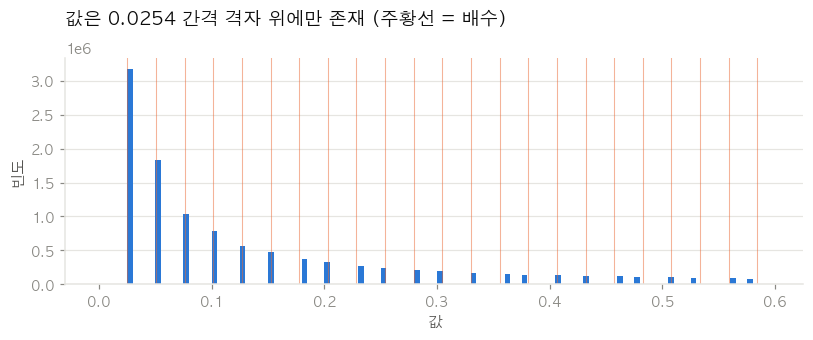

In [6]:
v  = pd.Series(grid[SEX_COLS+TMST_COLS].to_numpy().ravel()).dropna()
nz = np.unique(v[v>0].to_numpy())
print(f'비0 값 {int((v>0).sum()):,}개 · 고유값 {len(nz):,}개')
print('작은 값 24개:', np.round(nz[:24],3))

rows=[]
for q in [0.025, 0.0254, 0.0253, 0.0255, 1/40]:
    ok = np.isclose(np.round(np.round(nz/q)*q, 2), nz, atol=1e-9)
    first = nz[~ok][0] if (~ok).any() else np.nan
    rows.append(dict(양자후보=round(q,5), 설명된고유값=int(ok.sum()),
                     설명률=round(ok.mean()*100,1), 첫실패=round(float(first),2) if ok.all()==False else None))
print('\n', pd.DataFrame(rows).to_string(index=False))
best = max(np.arange(0.0240,0.0270,2e-6),
           key=lambda q: np.isclose(np.round(np.round(nz/q)*q,2), nz, atol=1e-9).mean())
print(f'\n격자탐색 최적 q = {best:.6f}   (설정값 QUANTUM = {QUANTUM})')
print('※ 0.025는 n=14(0.35 vs 실제 0.36)에서 깨진다. 0.0254가 정답.')

fig, ax = plt.subplots(figsize=(7.5,3.2))
h = v[(v>0)&(v<0.6)]
ax.hist(h, bins=np.arange(0,0.6,0.005), color=CAT[0])
for k in range(1,24): ax.axvline(k*QUANTUM, color=CAT[1], lw=0.7, alpha=0.5)
style(ax, f'값은 {QUANTUM} 간격 격자 위에만 존재 (주황선 = 배수)', '값', '빈도')
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/qc_quantum.png', bbox_inches='tight'); plt.show()

---
## Cell 6 · 주변분포 검산과 상향 편향

세 블록은 같은 총량의 분해이므로 `sum(성연령) = sum(시간대)`여야 합니다. **IQR**(Q3 − Q1, 가운데 50%가 흩어진 폭)로 흔들림을 봅니다.

셀이 작을수록 어긋나고, 결정적으로 **1보다 크게** 치우칩니다. 단순 반올림이면 대칭이라 중앙값이 1.000이어야 하므로, 이는 노이즈가 아니라 **편향**입니다. "칸에 사람이 있으면 최소 한 칸(0.0254)은 찍는" 바닥 규칙으로 보이며, 편향 크기가 칸 수에 비례합니다(시간대 24칸 > 성연령 12칸).

편향은 평균으로 상쇄되지 않습니다. 다만 *합산*에서는 발생하지 않습니다 — 다음 셀이 그걸 이용합니다.

여기서 실무 규칙 하나가 나옵니다: **비중의 분모는 반드시 같은 블록 안에서** 가져올 것. 고령 비중은 성연령 합으로, 야간 비중은 시간대 합으로 나눕니다.

시간대합 ÷ 성연령합  (이론값 1.000)
                    행수     중앙값      Q1      Q3     IQR
b                                                     
(0.0, 0.5]      126886  1.3125  1.1053  1.7368  0.6316
(0.5, 1.0]       75300  1.0460  0.9867  1.1053  0.1186
(1.0, 3.0]      106347  1.0185  0.9948  1.0455  0.0506
(3.0, 10.0]      84569  1.0031  0.9959  1.0110  0.0150
(10.0, 30.0]     52618  1.0007  0.9984  1.0031  0.0048
(30.0, 100.0]    44908  1.0001  0.9994  1.0009  0.0015
(100.0, 300.0]   32861  1.0000  0.9998  1.0003  0.0005
(300.0, inf]     38574  1.0000  1.0000  1.0001  0.0001

단순 반올림이면 중앙값이 1.000이어야 하는데 작은 셀에서 1보다 크다.
'칸에 사람이 있으면 최소 한 칸(0.0254)은 찍는' 바닥 규칙으로 보이며,
편향 크기가 칸 수에 비례한다(시간대 24칸 > 성연령 12칸). 대칭 노이즈가 아니라 편향.
-> 평균으로는 상쇄되지 않지만 '합산'에서는 발생하지 않는다 (Cell 7).


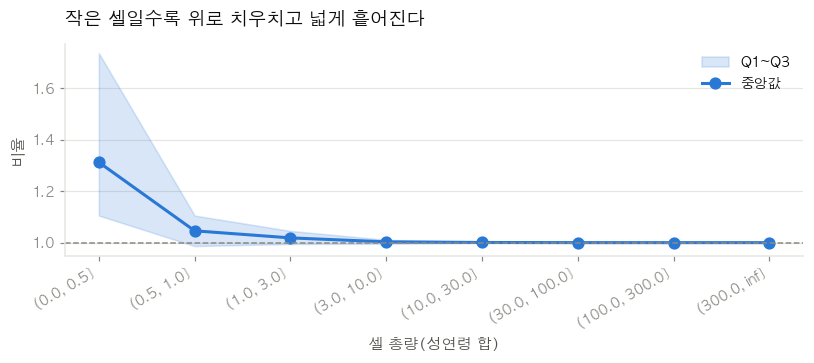

In [7]:
ok = grid[(grid.SEX_SUM>0) & grid[TMST_COLS].notna().all(axis=1) & grid[SEX_COLS].notna().all(axis=1)].copy()
ok['r'] = ok.TM_SUM/ok.SEX_SUM
tab = (ok.assign(b=pd.cut(ok.SEX_SUM, [0,0.5,1,3,10,30,100,300,np.inf]))
         .groupby('b', observed=True)
         .agg(행수=('r','size'), 중앙값=('r','median'),
              Q1=('r', lambda s:s.quantile(.25)), Q3=('r', lambda s:s.quantile(.75)))
         .assign(IQR=lambda t: t.Q3-t.Q1).round(4))
print('시간대합 ÷ 성연령합  (이론값 1.000)'); print(tab.to_string())
print("""
단순 반올림이면 중앙값이 1.000이어야 하는데 작은 셀에서 1보다 크다.
'칸에 사람이 있으면 최소 한 칸(0.0254)은 찍는' 바닥 규칙으로 보이며,
편향 크기가 칸 수에 비례한다(시간대 24칸 > 성연령 12칸). 대칭 노이즈가 아니라 편향.
-> 평균으로는 상쇄되지 않지만 '합산'에서는 발생하지 않는다 (Cell 7).""")

fig, ax = plt.subplots(figsize=(7.5,3.4))
xi = np.arange(len(tab))
ax.fill_between(xi, tab.Q1, tab.Q3, color=CAT[0], alpha=0.18, label='Q1~Q3')
ax.plot(xi, tab.중앙값, marker='o', ms=7, color=CAT[0], label='중앙값')
ax.axhline(1.0, color=MUTED, lw=1, ls='--')
ax.set_xticks(xi); ax.set_xticklabels([str(i) for i in tab.index], rotation=30, ha='right')
ax.legend(loc='upper right')
style(ax, '작은 셀일수록 위로 치우치고 넓게 흩어진다', '셀 총량(성연령 합)', '비율')
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/qc_marginal.png', bbox_inches='tight'); plt.show()

---
# Phase 2 — 공간 단위 결정

## Cell 7 · 집계 수준 비교 ⭐

같은 검산을 격자 / 블록[:13] / 행정동에서 반복합니다. 춘천 기준 비율 IQR이 격자 0.0922에서 집계구 0.0005로 **184배** 줄어듭니다.

합산은 양자화 편향을 일으키지 않기 때문입니다(0.03 + 0.03 = 0.06은 정확). **그리고 격자를 한 행도 버리지 않습니다.**

초기에 검토했던 임계값 필터링(일평균 3명 미만 제외)은 폐기했습니다. 춘천 격자의 72%가 해당되는데, 고립 분석에서 저밀도 지역을 일괄 제외하면 **관심 대상을 체계적으로 배제하는 선택 편의**가 생기기 때문입니다. 독거노인은 원래 인구가 희박한 곳에 삽니다.

                  단위수          총량중앙값   비율중앙값   비율IQR
집계수준    REGION                                      
격자      강남구     15351     118.000000  1.0000  0.0007
        춘천시     83968       1.200000  1.0068  0.0922
블록[:13] 강남구      1082    1170.599976  1.0000  0.0002
        춘천시       557     841.400024  1.0001  0.0005
행정동     강남구        22  281013.400000  1.0000  0.0000
        춘천시        25   58855.600000  1.0004  0.0084

합산은 양자화 편향을 일으키지 않는다 (0.03 + 0.03 = 0.06 은 정확).
-> 격자를 한 행도 버리지 않고 상위 단위로 올린다. 임계값 필터링은 쓰지 않는다.


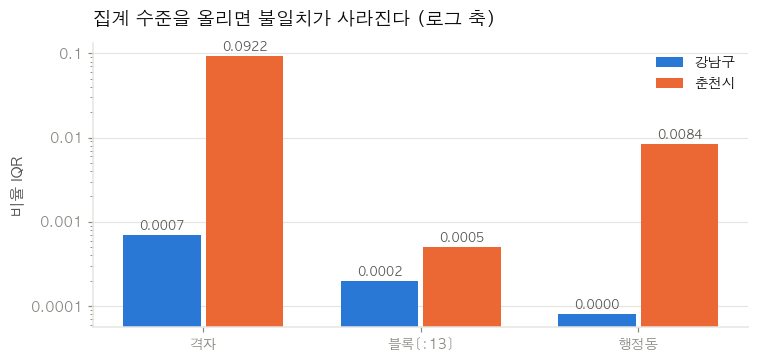

In [8]:
def consistency(level, df=None):
    df = grid if df is None else df
    a = df.copy() if level=='CELL' else df.groupby(['REGION',level,'STD_YM'], as_index=False)[VAL_COLS].sum()
    a = a.assign(S=a[SEX_COLS].sum(axis=1), T=a[TMST_COLS].sum(axis=1))
    a = a[a.S>0]; a = a.assign(r=a['T']/a['S'])
    g = a.groupby('REGION')                       # groupby.apply 미사용 = pandas 버전 무관
    return pd.DataFrame({'단위수':(g.size()/len(MONTHS)).round().astype(int),
        '총량중앙값':g.S.median().round(1), '비율중앙값':g.r.median().round(4),
        '비율IQR':(g.r.quantile(.75)-g.r.quantile(.25)).round(4)})

cmp = pd.concat({'격자':consistency('CELL'), '블록[:13]':consistency('JIP'),
                 '행정동':consistency('ADM')}, names=['집계수준'])
print(cmp.to_string())
print("""
합산은 양자화 편향을 일으키지 않는다 (0.03 + 0.03 = 0.06 은 정확).
-> 격자를 한 행도 버리지 않고 상위 단위로 올린다. 임계값 필터링은 쓰지 않는다.""")

fig, ax = plt.subplots(figsize=(7,3.4)); lv=['격자','블록[:13]','행정동']; w=0.38; FLOOR=8e-5
for i,(reg,c) in enumerate(zip(REGION.values(), CAT)):
    y=[cmp.loc[(l,reg),'비율IQR'] for l in lv]
    b=ax.bar(np.arange(3)+(i-0.5)*w, [max(t,FLOOR) for t in y], w*0.94, color=c, label=reg)
    ax.bar_label(b, labels=[f'{t:.4f}' for t in y], fontsize=8, color=INK2, padding=2)
ax.set_xticks(range(3)); ax.set_xticklabels(lv); ax.set_yscale('log')
ax.set_ylim(FLOOR*0.7, None); ax.legend(loc='upper right'); plainlog(ax)
style(ax, '집계 수준을 올리면 불일치가 사라진다 (로그 축)', None, '비율 IQR')
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/p1_level.png', bbox_inches='tight'); plt.show()

---
## Cell 8 · 공식 집계구 공간 할당 ⭐

v3는 `BLOCK_CD[:13]`을 집계구로 **추정**했습니다. SGIS 집계구 경계를 받아 검증한 결과:

- 코드 변환 조인(`[:8] + '0' + [8:13]`)은 형식상 맞지만 **공간적으로 13.2%만 일치**
- 우리 단위 1개 ↔ 공식 집계구 1개가 **중앙값 2:2로 쪼개짐**
- 반면 **좌표 기반 폴리곤 할당은 100% 성공**

집계 품질은 동일합니다(비율 IQR이 소수점까지 같음). 따라서 **공식 집계구를 1급 단위로 씁니다.** 얻는 것은 셋입니다 — SGIS 통계가 코드로 바로 붙고, 폴리곤 코로플레스가 가능해지고, 보고서에 "추정"이 아니라 "공식 경계에 공간 결합"이라 쓸 수 있습니다.

`geopandas` 없이 shapefile을 직접 파싱합니다(`matplotlib.path`로 점-포함 판정). 경계 파일이 없으면 `BLOCK_CD[:13]`로 자동 대체되며 경고를 출력합니다.

In [9]:
def read_dbf(p):
    b=open(p,'rb').read(); nrec,hlen,rlen=struct.unpack('<IHH',b[4:12])
    fields,off=[],32
    while b[off]!=0x0D:
        fields.append((b[off:off+11].split(b'\0')[0].decode('utf-8','replace'), b[off+16])); off+=32
    rows=[]
    for i in range(nrec):
        r,pos,rec=b[hlen+i*rlen:hlen+(i+1)*rlen],1,{}
        for n,l in fields: rec[n]=r[pos:pos+l].decode('utf-8','replace').strip(); pos+=l
        rows.append(rec)
    return pd.DataFrame(rows)

def read_shp_polygons(p):
    """shapefile 폴리곤(type 5)을 Path 목록으로. geopandas 불필요."""
    b=open(p,'rb').read(); n=len(b); off=100; out=[]
    while off < n:
        _, clen = struct.unpack('>II', b[off:off+8]); off+=8; end=off+clen*2
        if struct.unpack('<i', b[off:off+4])[0] != 5: off=end; continue
        box = struct.unpack('<4d', b[off+4:off+36])
        nparts, npts = struct.unpack('<ii', b[off+36:off+44])
        parts = np.frombuffer(b, dtype='<i4', count=nparts, offset=off+44)
        pts = np.frombuffer(b, dtype='<f8', count=npts*2, offset=off+44+nparts*4).reshape(-1,2)
        verts, codes, bnd = [], [], list(parts)+[npts]
        for i in range(nparts):
            ring = pts[bnd[i]:bnd[i+1]]
            if len(ring) < 3: continue
            verts.append(ring)
            c = np.full(len(ring), Path.LINETO, np.uint8); c[0]=Path.MOVETO; c[-1]=Path.CLOSEPOLY
            codes.append(c)
        out.append((Path(np.vstack(verts), np.concatenate(codes)) if verts else None, box, pts))
        off = end
    return out

def assign_polygon(xy, shp, dbf, code_col=None):
    att = read_dbf(dbf)
    code_col = code_col or [c for c in att.columns if 'OA' in c.upper()][0]
    polys = read_shp_polygons(shp)
    assert len(polys)==len(att), f'shp {len(polys)} != dbf {len(att)}'
    res = np.full(len(xy), '', dtype=object); X,Y = xy[:,0], xy[:,1]
    for (path, box, _), code in zip(polys, att[code_col]):
        if path is None: continue
        idx = np.flatnonzero((X>=box[0])&(X<=box[2])&(Y>=box[1])&(Y<=box[3]))
        if not len(idx): continue
        res[idx[path.contains_points(xy[idx])]] = code
    return res

shp_files = {os.path.basename(p).split('_')[2]: p for p in glob.glob(f'{OA_DIR}/bnd_oa_*.shp')}
USE_OFFICIAL = all(r in shp_files for r in REGION)
print('집계구 경계 파일:', {k: os.path.basename(v) for k,v in shp_files.items()} or '없음')

cells = grid[['SGG','X_COORD','Y_COORD']].drop_duplicates().reset_index(drop=True)
if USE_OFFICIAL:
    oa = np.full(len(cells), '', dtype=object)
    for reg in REGION:
        m = (cells.SGG==reg).to_numpy()
        oa[m] = assign_polygon(cells.loc[m,['X_COORD','Y_COORD']].to_numpy(),
                               shp_files[reg], shp_files[reg].replace('.shp','.dbf'))
    cells['OA'] = oa
    print(f'폴리곤 내부 할당: {(cells.OA!="").mean()*100:.1f}% ({(cells.OA=="").sum():,}개 실패)')
    grid = grid.merge(cells, on=['SGG','X_COORD','Y_COORD'], how='left')
    grid = grid[grid.OA.fillna('')!='']
    UNIT = 'OA'; UNIT_NAME = '공식 집계구'
else:
    print('※ 경계 파일이 없어 BLOCK_CD[:13]을 집계 단위로 사용합니다.')
    print('   코드 변환 조인은 공간 할당과 13%만 일치하므로, 경계 파일 확보를 권장합니다.')
    grid['OA'] = grid.JIP; UNIT='OA'; UNIT_NAME='블록[:13] (근사)'
print(f'\n분석 단위: {UNIT_NAME} · {grid.OA.nunique():,}개')
if USE_OFFICIAL:
    print(pd.concat({'블록[:13]':consistency('JIP'), '공식 집계구':consistency('OA')},
                    names=['집계수준']).to_string())

집계구 경계 파일: {'32010': 'bnd_oa_32010_2025_2Q.shp', '11230': 'bnd_oa_11230_2025_2Q.shp'}
폴리곤 내부 할당: 100.0% (2개 실패)

분석 단위: 공식 집계구 · 1,693개
                 단위수        총량중앙값   비율중앙값   비율IQR
집계수준    REGION                                   
블록[:13] 강남구     1082  1170.599976  1.0000  0.0002
        춘천시      557   841.400024  1.0001  0.0005
공식 집계구  강남구     1094  1118.000000  1.0000  0.0002
        춘천시      599   795.700012  1.0001  0.0005


---
## Cell 9 · 집계구 패널 구축

좌표는 격자의 **인구 가중 중심**을 씁니다. 단순 평균이면 사람 없는 산지로 대표점이 끌려갑니다.

한 집계구가 여러 행정동 코드에 걸치는 경우가 있습니다(SK 블록 경계와 공식 집계구 경계가 다르기 때문). 인구 가중 최빈 행정동 하나로 고정해 중복 행을 막습니다.

In [10]:
xy = (grid.assign(wx=grid.X_COORD*grid.DAILY, wy=grid.Y_COORD*grid.DAILY)
          .groupby('OA').agg(wx=('wx','sum'), wy=('wy','sum'), w=('DAILY','sum'),
                             mx=('X_COORD','mean'), my=('Y_COORD','mean')))
xy['X'] = np.where(xy.w>0, xy.wx/xy.w.replace(0,np.nan), xy.mx)
xy['Y'] = np.where(xy.w>0, xy.wy/xy.w.replace(0,np.nan), xy.my)

# 한 집계구가 여러 행정동 코드에 걸칠 수 있으므로(경계 불일치) 인구 가중 최빈 ADM 하나로 고정
adm_of = (grid.groupby(['OA','ADM']).DAILY.sum().reset_index()
              .sort_values('DAILY', ascending=False).drop_duplicates('OA').set_index('OA').ADM)
print(f'행정동 2개 이상에 걸친 집계구: {(grid.groupby("OA").ADM.nunique()>1).sum()}개 -> 최빈 행정동으로 고정')
oa = grid.groupby(['REGION','OA','STD_YM'], as_index=False)[VAL_COLS].sum()
oa['ADM'] = oa.OA.map(adm_of)
oa = oa.merge(xy[['X','Y']], left_on='OA', right_index=True, how='left')
oa['YM']      = pd.to_datetime(oa.STD_YM.astype(str), format='%Y%m')
oa['DAILY']   = oa[DOW_COLS].sum(axis=1)/7
oa['SEX_SUM'] = oa[SEX_COLS].sum(axis=1)
oa['TM_SUM']  = oa[TMST_COLS].sum(axis=1)
oa['NCELL']   = grid.groupby(['OA','STD_YM']).size().reindex(
                  pd.MultiIndex.from_frame(oa[['OA','STD_YM']])).to_numpy()
print(f'패널 {len(oa):,}행 = {oa.OA.nunique():,}개 × {len(MONTHS)}개월')
print(oa.groupby('REGION').agg(단위수=('OA','nunique'), 격자수중앙값=('NCELL','median'),
      일평균인구중앙값=('DAILY','median')).round(1).to_string())
bal = oa.groupby('OA').STD_YM.nunique().value_counts().sort_index()
print('\n패널 균형(등장 개월 수):', bal.to_dict(), '· 격자는 전량 보존')

행정동 2개 이상에 걸친 집계구: 9개 -> 최빈 행정동으로 고정
패널 10,158행 = 1,693개 × 6개월
         단위수  격자수중앙값     일평균인구중앙값
REGION                           
강남구     1094     6.0  1119.199951
춘천시      599     7.0   793.900024

패널 균형(등장 개월 수): {6: 1693} · 격자는 전량 보존


---
# Phase 3 — 신호 추출

## Cell 10 · 신호 변수 산출

| 변수 | 정의 | 가설 |
|---|---|---|
| `CV_H` | 시간대 비중의 변동계수 | 낮을수록 평탄 = 유출입 없음 = 위험 |
| `NIGHT_SH` | 야간(22~05) 비중 | 높을수록 비이동 |
| `DAWN_SH` | 새벽(00~05) 비중 | 상주인구 근사 |
| `SR_60` | 60대+ ÷ 성연령 합 | 고령 비중 |
| `WKND` | 주말 ÷ 주중 | ★ Cell 18에서 방향 기각됨 |

주말비 극단값은 **같은 집계구가 6개월 내내 같은 값**을 보이므로 노이즈가 아니라 실재하는 주말 전용 지역(공원·종교시설)입니다. winsorize하지 않습니다.

REGION                 강남구        춘천시
DAILY    count    6564.000   3594.000
         mean     6733.983   3102.803
         std     18171.266   6390.581
         min        22.929     25.081
         25%       445.800    312.798
         50%      1119.219    793.884
         75%      3995.171   2820.092
         max    275040.312  70075.375
SR_60    count    6564.000   3594.000
         mean        0.216      0.247
         std         0.049      0.055
         min         0.103      0.089
         25%         0.175      0.218
         50%         0.216      0.237
         75%         0.250      0.264
         max         0.431      0.651
CV_H     count    6564.000   3594.000
         mean        0.581      0.566
         std         0.046      0.063
         min         0.425      0.371
         25%         0.548      0.525
         50%         0.576      0.558
         75%         0.615      0.599
         max         0.768      0.906
NIGHT_SH count    6564.000   3594.000
         mea

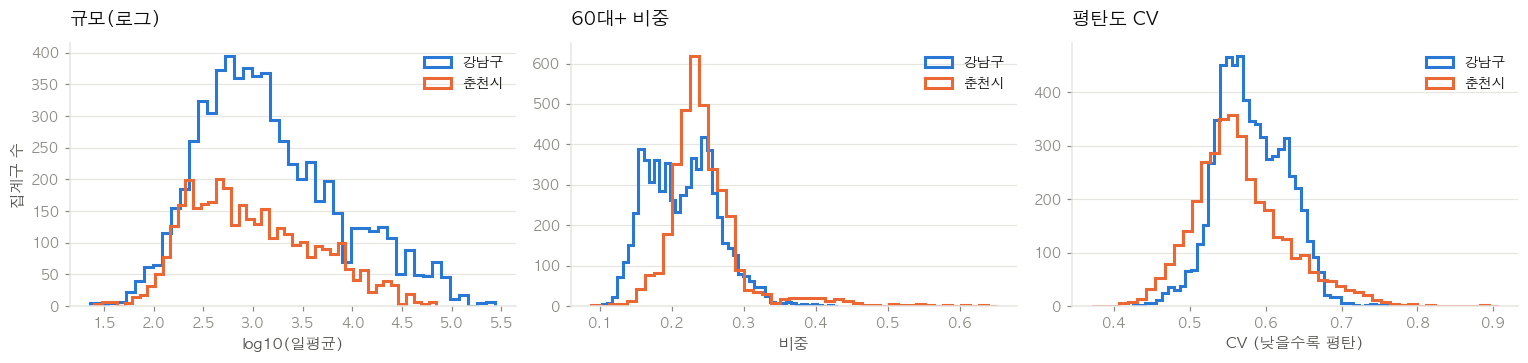

In [11]:
P = oa[TMST_COLS].to_numpy(float)
P = P / np.where(P.sum(1,keepdims=True)==0, np.nan, P.sum(1,keepdims=True))
oa['CV_H']     = P.std(axis=1)/P.mean(axis=1)                    # 낮을수록 평탄
oa['NIGHT_SH'] = oa[NIGHT].sum(axis=1)/oa.TM_SUM.replace(0,np.nan)
oa['DAWN_SH']  = oa[DAWN].sum(axis=1)/oa.TM_SUM.replace(0,np.nan)
oa['DAYNIGHT'] = oa[DAY].sum(axis=1)/oa[NIGHT].sum(axis=1).replace(0,np.nan)
oa['SR_60']    = oa[OLD_COLS].sum(axis=1)/oa.SEX_SUM.replace(0,np.nan)
oa['SR_W']     = oa[[c for c in SEX_COLS if c.startswith('WMAN')]].sum(axis=1)/oa.SEX_SUM.replace(0,np.nan)
_wd = oa[WD_COLS].sum(axis=1)/5; _we = oa[WE_COLS].sum(axis=1)/2
oa['WKND']     = np.where(_wd>0, _we/_wd, np.nan)
print(oa.groupby('REGION')[['DAILY','SR_60','CV_H','NIGHT_SH','WKND']]
        .describe(percentiles=[.25,.5,.75]).round(3).T.to_string())

# 주말비 극단값이 노이즈인지 실재 신호인지
ex = oa[oa.WKND>5].groupby('OA').WKND.agg(['size','mean','std'])
ex = ex[ex['size']==len(MONTHS)]
if len(ex):
    print(f'\n주말비 5 초과 & 6개월 지속: {len(ex)}개 · 월별 변동계수 중앙값 '
          f'{(ex["std"]/ex["mean"]).median():.3f} -> 노이즈가 아니라 주말 전용 지역. winsorize 안 함.')

fig, axes = plt.subplots(1,3, figsize=(14,3.4))
for (reg,g), c in zip(oa.groupby('REGION'), CAT):
    axes[0].hist(np.log10(g.DAILY[g.DAILY>0]), bins=45, histtype='step', lw=2, color=c, label=reg)
    axes[1].hist(g.SR_60.dropna(), bins=45, histtype='step', lw=2, color=c, label=reg)
    axes[2].hist(g.CV_H.dropna(), bins=45, histtype='step', lw=2, color=c, label=reg)
for a,t,x in zip(axes, ['규모(로그)','60대+ 비중','평탄도 CV'],
                 ['log10(일평균)','비중','CV (낮을수록 평탄)']):
    a.legend(loc='upper right'); style(a, t, x, '집계구 수' if a is axes[0] else None)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/p2_dist.png', bbox_inches='tight'); plt.show()

---
## Cell 11 · 지역 스케일 진단

"강남과 춘천 스케일을 맞춰야 하나"에 대한 정량적 답입니다. Cohen's d는 두 분포의 중심 차이를 표준편차 단위로 잽니다(0.2 미만이면 사실상 같은 분포).

집계구 전환으로 규모 차이가 166배에서 1.4배로 줄었고, **지표 변수 대부분이 d < 0.2**입니다. 비율 변수는 규모가 분자·분모에서 약분되기 때문입니다.

남는 건 고령 비중 하나인데 이건 **실재하는 사실이라 보정하면 안 됩니다.** 분위수 정규화로 두 지역 분포를 강제로 같게 만들면 찾으려는 신호를 지우게 됩니다.

**강남 유효성**도 함께 검증합니다. 일평균 축에서는 강남의 유동/상주 비율이 춘천의 2.3배로 불리하지만, **새벽(00~05) 축에서는 강남이 오히려 상주인구에 더 가깝습니다.** "강남은 구조적으로 측정 불가"라는 주장은 축에 따라 달라집니다.

In [12]:
cur = oa[oa.STD_YM==MONTHS[-1]]
def cohen_d(a,b):
    a,b = a.dropna(), b.dropna()
    return (a.mean()-b.mean())/np.sqrt((a.var(ddof=1)+b.var(ddof=1))/2)
g1 = cur[cur.REGION=='강남구']; g2 = cur[cur.REGION=='춘천시']
rows=[]
for v,nm in [('DAILY','규모(일평균)'),('CV_H','평탄도'),('SR_60','고령비중'),
             ('WKND','주말비'),('NIGHT_SH','야간비중')]:
    d = cohen_d(g1[v], g2[v])
    rows.append(dict(변수=nm, 강남중앙값=round(g1[v].median(),3), 춘천중앙값=round(g2[v].median(),3),
                     배수=round(abs(g1[v].median()/g2[v].median()),2) if g2[v].median() else np.nan,
                     Cohen_d=round(d,2),
                     판정='무시' if abs(d)<0.2 else ('작음' if abs(d)<0.5 else ('중간' if abs(d)<0.8 else '큼'))))
print(pd.DataFrame(rows).to_string(index=False))
print('''
비율 변수는 규모가 분자·분모에서 약분되므로 지역 간 스케일 조정이 불필요하다.
고령비중 차이는 실재하는 사실이므로 보정하지 않는다 (분위수 정규화 금지).
지역 간 '절대' 비교가 필요하면 상주인구 분모를 붙이는 것이 유일한 방법 (Cell 17).''')

# 강남 유효성: 일평균 축 vs 새벽 축
print('\n[유동/상주 비율] 일평균 축에서는 강남이 불리하지만 새벽 축에서는 다르다')
for reg, g in cur.groupby('REGION'):
    tot = g.DAILY.sum(); dawn = g[DAWN].sum().sum()/len(DAWN)
    print(f'  {reg}: 일평균 {tot/POP_REF[reg]:>6.2f}배 · 새벽(00~05) {dawn/POP_REF[reg]:>5.2f}배')
print('  -> 새벽 축은 상주인구에 근접하므로 강남에서도 주민 고립 측정이 가능하다.')

     변수    강남중앙값   춘천중앙값   배수  Cohen_d 판정
규모(일평균) 1055.589 753.140 1.40     0.27 작음
    평탄도    0.581   0.572 1.02     0.10 무시
   고령비중    0.218   0.239 0.91    -0.59 중간
    주말비    1.097   1.339 0.82    -0.09 무시
   야간비중    0.108   0.115 0.94    -0.18 무시

비율 변수는 규모가 분자·분모에서 약분되므로 지역 간 스케일 조정이 불필요하다.
고령비중 차이는 실재하는 사실이므로 보정하지 않는다 (분위수 정규화 금지).
지역 간 '절대' 비교가 필요하면 상주인구 분모를 붙이는 것이 유일한 방법 (Cell 17).

[유동/상주 비율] 일평균 축에서는 강남이 불리하지만 새벽 축에서는 다르다
  강남구: 일평균  13.74배 · 새벽(00~05)  0.10배
  춘천시: 일평균   6.08배 · 새벽(00~05)  0.06배
  -> 새벽 축은 상주인구에 근접하므로 강남에서도 주민 고립 측정이 가능하다.


---
## Cell 12 · 공간 구조 (유의성 검정 포함)

`libpysal` 없이 `cKDTree`로 Moran's I와 LISA를 구현했습니다.

**v3에는 유의성 검정이 없었습니다.** 조건부 순열 검정(999회)을 붙이자 유의한 저활동 군집(LL)이 강남 478→145, 춘천 235→69로 줄었습니다. **70% 이상이 우연 수준**이었습니다.

또 하나의 한계: 춘천에서 8이웃 평균 거리가 96m~12,346m로 **129배** 차이납니다(강남은 7배). 시내와 농촌에서 "이웃"이 전혀 다른 공간 규모를 의미합니다. 집계구가 면적이 아니라 인구 기준으로 획정되기 때문이며, 최종 지수에는 LISA를 쓰지 않으므로 한계로 명시하고 진행합니다.

강남구: Moran's I = 0.382  n=1,094  · 8이웃 평균거리 172m (최대/최소 6배)
춘천시: Moran's I = 0.220  n=599  · 8이웃 평균거리 217m (최대/최소 131배)
※ 이웃 거리 편차가 크면(춘천) 공간 군집 해석의 신뢰도가 낮다 — 한계로 명시할 것.
  강남구: LL 단순 494 -> 유의 139
  춘천시: LL 단순 245 -> 유의 60


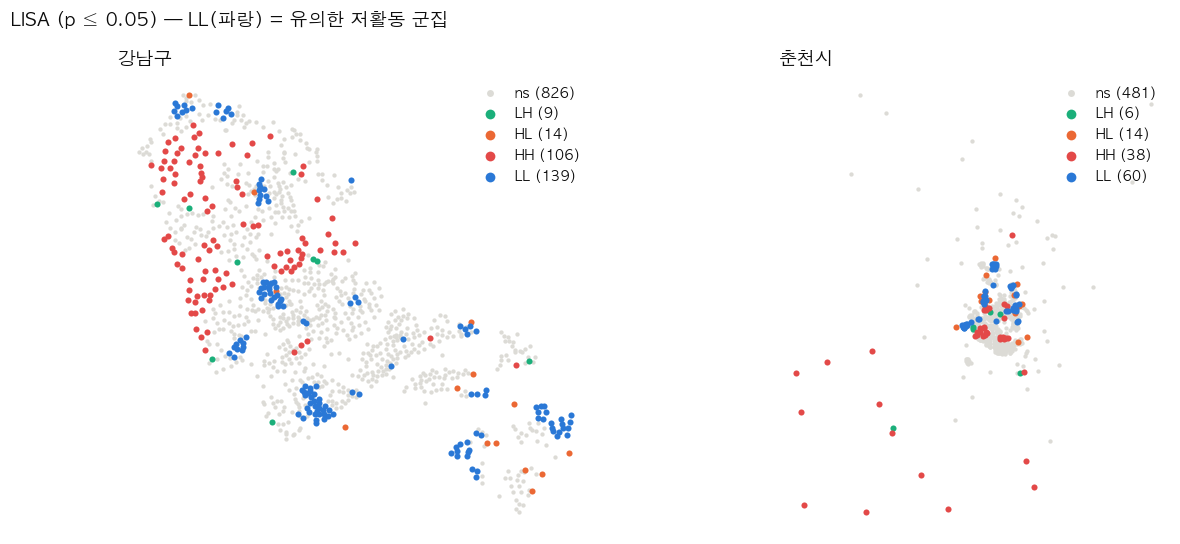

In [13]:
def knn_lag(XY, z, k=8):
    _, nb = cKDTree(XY).query(XY, k=min(k,len(XY)-1)+1); return z[nb[:,1:]].mean(axis=1), nb[:,1:]
def morans_i(XY, v, k=8):
    v = np.asarray(v,float)-np.mean(v); lag,_ = knn_lag(XY, v, k); return float(v@lag/(v@v))
def lisa(XY, v, k=8, nsim=999, alpha=0.05, seed=42):
    """Local Moran's I + 조건부 순열 유의성 검정."""
    rng = np.random.default_rng(seed)
    z = (np.asarray(v,float)-np.mean(v))/np.std(v); n=len(z); k=min(k,n-1)
    _, nb = cKDTree(XY).query(XY, k=k+1); nb = nb[:,1:]
    lag = z[nb].mean(1); Ii = z*lag
    r = rng.integers(0, n-1, size=(nsim,n,k)); r += (r >= np.arange(n)[None,:,None])
    sim = z[None,:]*z[r].mean(2)
    pval = (np.sum(np.abs(sim)>=np.abs(Ii)[None,:], axis=0)+1)/(nsim+1)
    lab = np.where((z>0)&(lag>0),'HH', np.where((z<0)&(lag<0),'LL',
          np.where((z>0)&(lag<0),'HL','LH')))
    return lab, pval, np.where(pval<=alpha, lab, 'ns')

for reg, g in cur.groupby('REGION'):
    XY = g[['X','Y']].to_numpy()
    d,_ = cKDTree(XY).query(XY, k=9); rad = d[:,1:].mean(1)
    print(f"{reg}: Moran's I = {morans_i(XY, np.log1p(g.DAILY.to_numpy())):.3f}  n={len(g):,}"
          f"  · 8이웃 평균거리 {np.median(rad):.0f}m (최대/최소 {rad.max()/rad.min():.0f}배)")
print('※ 이웃 거리 편차가 크면(춘천) 공간 군집 해석의 신뢰도가 낮다 — 한계로 명시할 것.')

fig, axes = plt.subplots(1,2, figsize=(12,5))
LIS = {'ns':'#dcdbd6','LH':CAT[2],'HL':CAT[1],'HH':CAT[7],'LL':CAT[0]}
for ax, reg in zip(axes, REGION.values()):
    g = cur[cur.REGION==reg]
    lab, pval, sig = lisa(g[['X','Y']].to_numpy(), np.log1p(g.DAILY.to_numpy()))
    for k_ in ['ns','LH','HL','HH','LL']:
        m = sig==k_
        ax.scatter(g.X[m], g.Y[m], c=LIS[k_], s=8 if k_=='ns' else 16, linewidths=0,
                   label=f'{k_} ({m.sum():,})')
    nomap(ax, reg); ax.legend(loc='upper right', markerscale=1.6)
    print(f'  {reg}: LL 단순 {int((lab=="LL").sum())} -> 유의 {int(((lab=="LL")&(pval<=.05)).sum())}')
fig.suptitle('LISA (p ≤ 0.05) — LL(파랑) = 유의한 저활동 군집', x=0.005, ha='left',
             fontsize=12, fontweight='600')
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/p3_lisa.png', bbox_inches='tight'); plt.show()

---
## Cell 13 · 시간대 프로파일 군집

**핵심 가설: 하루 종일 변동이 없는 곳 = 유입도 유출도 없는 곳 = 은둔·고립의 대리 신호.**

정규화를 두 번 합니다. 그 이유를 이 셀이 직접 측정해서 보여줍니다(상관비 eta²).

```
① 원본(사람 수)      크기 0.469   진폭 0.104   ← 군집이 크기로 갈림
② 비중만             크기 0.209   진폭 0.569   ← 군집이 진폭으로 갈림
③ 비중+z표준화       크기 0.057   진폭 0.296   ← 타이밍만 남음
```

1차 정규화가 **크기**를, 2차 정규화가 **진폭**을 제거합니다. 진폭(평탄도)을 일부러 빼는 이유는 그것이 `CV_H`로 이미 지수에 직접 들어가기 때문입니다. 군집까지 진폭으로 갈리면 같은 정보를 두 번 쓰게 되고, Cell 17의 중복 진단이 무의미해집니다.

역할 분리입니다 — **군집은 "어떤 성격의 공간인가", `CV_H`는 "얼마나 위험한가"**.

라벨은 군집 간 상대 순위로만 붙입니다. 주거형/상업형 해석은 지도와 대조해 직접 확정하세요.

※ 라벨은 군집 간 상대 순위. 주거형/상업형 해석은 지도와 대조해 직접 확정할 것.
   평탄1/5 = 가장 평탄 = 고립 가설 후보

                              n        규모중앙값  평탄도CV   야간비중   고령비중
CLUSTER                                                          
C0 peak17시 · 야간3/5 · 평탄1/5  328  1193.426025  0.565  0.107  0.259
C1 peak13시 · 야간1/5 · 평탄5/5   96  2704.449951  0.666  0.078  0.318
C2 peak17시 · 야간5/5 · 평탄2/5  426   456.256012  0.566  0.123  0.207
C3 peak17시 · 야간4/5 · 평탄3/5  331  1181.548950  0.577  0.112  0.223
C4 peak13시 · 야간2/5 · 평탄4/5  512  1151.803955  0.604  0.106  0.213

지역 × 군집 (%):
CLUSTER  C0 peak17시 · 야간3/5 · 평탄1/5  C1 peak13시 · 야간1/5 · 평탄5/5  C2 peak17시 · 야간5/5 · 평탄2/5  C3 peak17시 · 야간4/5 · 평탄3/5  C4 peak13시 · 야간2/5 · 평탄4/5
REGION                                                                                                                                             
강남구                            30.0                         0.7                        31.7                         5.7                        31.9
춘천시

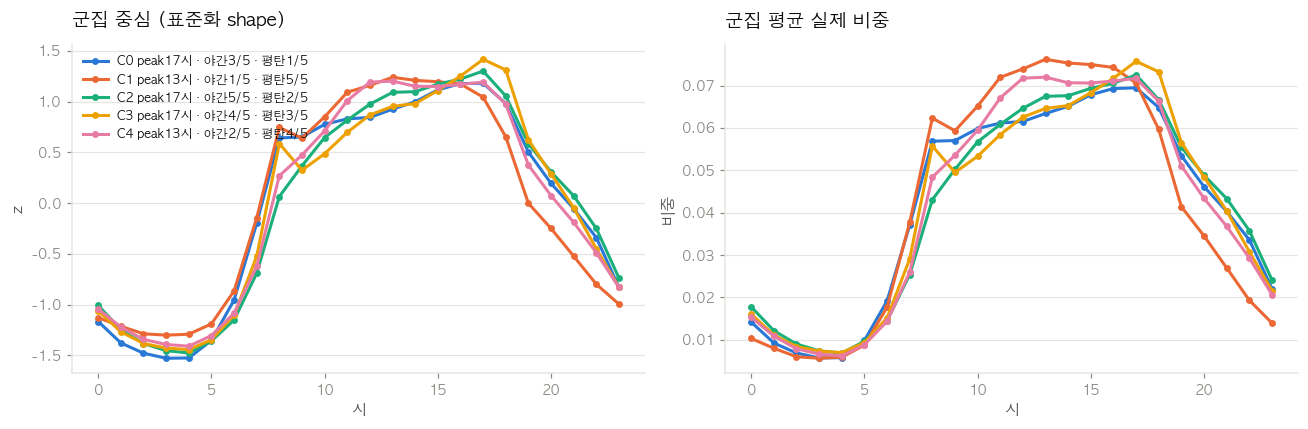

In [14]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
m = (oa.STD_YM==MONTHS[-1]).to_numpy()
Pc = P[m]; Z = (Pc-Pc.mean(1,keepdims=True))/Pc.std(1,keepdims=True)
K = 5
km = KMeans(K, n_init=10, random_state=42).fit(Z)
cen = pd.DataFrame(km.cluster_centers_, columns=range(24))
lab0 = pd.Series(km.labels_, index=oa.index[m])
_st = oa.loc[m].assign(_c=lab0).groupby('_c').agg(night=('NIGHT_SH','mean'), flat=('CV_H','mean'))
_st['r_night']=_st.night.rank().astype(int); _st['r_flat']=_st.flat.rank().astype(int)
names = {int(c): f'C{int(c)} peak{int(np.argmax(cen.loc[c])):02d}시 '
                 f'· 야간{int(r.r_night)}/{K} · 평탄{int(r.r_flat)}/{K}' for c,r in _st.iterrows()}
oa.loc[m,'CLUSTER'] = lab0.map(names)
print('※ 라벨은 군집 간 상대 순위. 주거형/상업형 해석은 지도와 대조해 직접 확정할 것.')
print('   평탄1/5 = 가장 평탄 = 고립 가설 후보\n')
print(oa[m].groupby('CLUSTER').agg(n=('DAILY','size'), 규모중앙값=('DAILY','median'),
      평탄도CV=('CV_H','mean'), 야간비중=('NIGHT_SH','mean'), 고령비중=('SR_60','mean')).round(3).to_string())
print('\n지역 × 군집 (%):')
print((pd.crosstab(oa[m].REGION, oa[m].CLUSTER, normalize='index')*100).round(1).to_string())

# 정규화 단계별로 군집이 무엇을 잡는지 (두 번 정규화하는 이유)
def eta2(lab, x):
    gm=x.mean(); return sum(((x[lab==c].mean()-gm)**2)*np.sum(lab==c) for c in np.unique(lab))/((x-gm)**2).sum()
A = oa.loc[m, TMST_COLS].to_numpy(float); SZ = np.log1p(oa.loc[m,'DAILY'].to_numpy()); CVv = oa.loc[m,'CV_H'].to_numpy()
print('\n정규화 단계별 군집이 설명하는 것 (eta²)')
for nm, M in [('① 원본(사람 수)',A), ('② 비중만',Pc), ('③ 비중+z표준화',Z)]:
    l = KMeans(K, n_init=10, random_state=42).fit_predict(M)
    print(f'  {nm:<18} 크기 {eta2(l,SZ):.3f}   진폭(평탄도) {eta2(l,CVv):.3f}')
print('  -> ①은 크기, ②는 진폭에 지배된다. ③이라야 "언제 활동하는가"(타이밍)만 남는다.')
print('     진폭은 CV_H로 따로 지수에 넣으므로 군집과 중복되면 안 된다.')

fig, axes = plt.subplots(1,2, figsize=(12,4))
for c in range(K):
    axes[0].plot(range(24), cen.loc[c], color=CAT[c], label=names[c], marker='o', ms=3.5)
    axes[1].plot(range(24), Pc[km.labels_==c].mean(axis=0), color=CAT[c], marker='o', ms=3.5)
axes[0].legend(loc='upper left', fontsize=8)
style(axes[0], '군집 중심 (표준화 shape)', '시', 'z'); style(axes[1], '군집 평균 실제 비중', '시', '비중')
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/p4_cluster.png', bbox_inches='tight'); plt.show()

---
## Cell 14 · 요일 구조와 6개월 변화

12월 하락이 한파에 의한 계절성인지 실제 감소인지 구분해야 합니다. 관측이 6점뿐이라 추세는 보조 변수로만 쓰고 가중치를 낮게 줍니다.

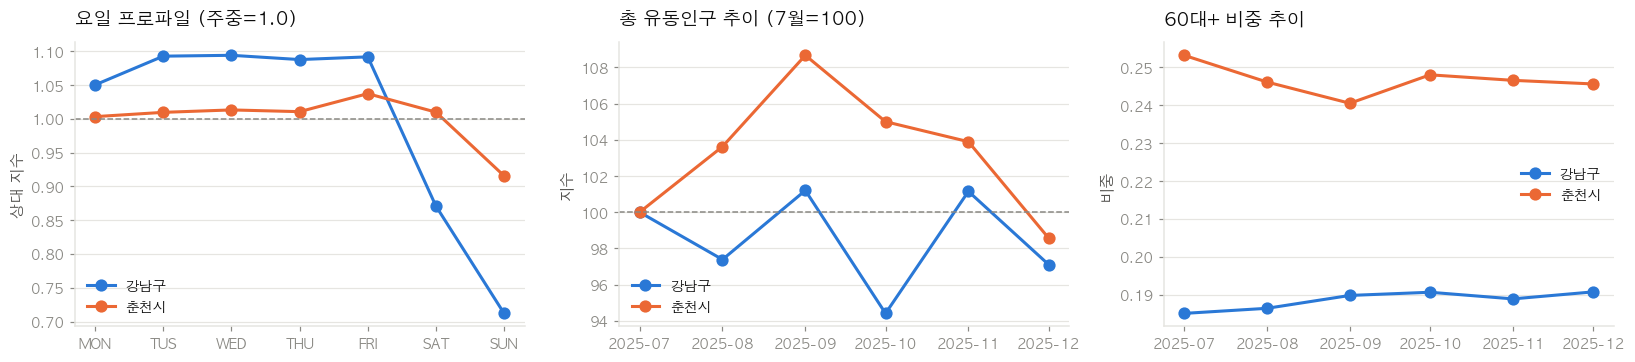

집계구 추세 (log 기울기/월):
count    1693.0000
mean       -0.0130
std         0.0344
min        -0.2185
5%         -0.0787
50%        -0.0078
95%         0.0270
max         0.2077


In [15]:
dwp = oa.groupby('REGION')[DOW_COLS].mean(); dwp = dwp.div(dwp.mean(axis=1), axis=0)
ts  = oa.groupby(['REGION','YM']).DAILY.sum().reset_index()
ts['IDX'] = ts.groupby('REGION').DAILY.transform(lambda s: s/s.iloc[0]*100)
_s  = oa.groupby(['REGION','YM'])[SEX_COLS].sum()
o60 = (_s[OLD_COLS].sum(axis=1)/_s.sum(axis=1)).rename('SR60').reset_index()

fig, axes = plt.subplots(1,3, figsize=(15,3.4))
for (reg,r), c in zip(dwp.iterrows(), CAT): axes[0].plot(DOW_ABBR, r.values, marker='o', ms=7, color=c, label=reg)
axes[0].axhline(1.0, color=MUTED, lw=1, ls='--'); axes[0].legend(loc='lower left')
style(axes[0], '요일 프로파일 (주중=1.0)', None, '상대 지수')
for (reg,g), c in zip(ts.groupby('REGION'), CAT): axes[1].plot(g.YM, g.IDX, marker='o', ms=7, color=c, label=reg)
axes[1].axhline(100, color=MUTED, lw=1, ls='--'); axes[1].legend(loc='lower left')
style(axes[1], '총 유동인구 추이 (7월=100)', None, '지수')
for (reg,g), c in zip(o60.groupby('REGION'), CAT): axes[2].plot(g.YM, g.SR60, marker='o', ms=7, color=c, label=reg)
axes[2].legend(loc='center right'); style(axes[2], '60대+ 비중 추이', None, '비중')
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/p5_time.png', bbox_inches='tight'); plt.show()

xg = np.arange(len(MONTHS)) - (len(MONTHS)-1)/2
def slope(s):
    s = s.reindex(MONTHS); k = s.notna().to_numpy()
    return np.polyfit(xg[k], np.log1p(s[k].to_numpy()), 1)[0] if k.sum()>=4 else np.nan
TREND = oa.pivot_table(index='OA', columns='STD_YM', values='DAILY', aggfunc='first').apply(slope, axis=1)
print('집계구 추세 (log 기울기/월):'); print(TREND.describe(percentiles=[.05,.5,.95]).round(4).to_string())

---
# Phase 4 — 외부 데이터 결합

## Cell 15 · SGIS 행정구역 통계

유동인구는 flow라 **분모(상주인구)** 없이는 "적다"를 해석할 수 없습니다. 상주 2,000명에 유동 800명인 곳과 상주 200명에 유동 800명인 곳은 정반대 의미인데 현재 지표는 구분하지 못합니다.

그리고 고립의 가장 직접적인 요인인 **1인가구**가 통신 데이터에 아예 없습니다.

SGIS 행정구역 통계는 `기준연도 / 행정구역코드 / 통계항목 / 통계값` 롱포맷이고 cp949입니다. 쓰는 항목:

```
to_in_001  총인구      to_ga_001  총가구수
ga_sd_005  1인가구     in_age_014 65~69세
```

행정동(8자리) 단위라 집계구에 직접 붙지는 않지만, 행정동 레벨 분모로 쓸 수 있고 최종 산출물이 행정동 단위이므로 실제 정책 결론이 나오는 지점입니다.

**집계구 단위 통계**를 받으면 `SGIS_OA`에 넣고 `OA` 코드로 직접 조인하면 됩니다. 경계와 같은 연도(2025년 2분기)로 받으셔야 코드가 맞습니다.

In [16]:
def read_any(p):
    for e in ['utf-8-sig','cp949','euc-kr']:
        try: return pd.read_csv(p, encoding=e, dtype=str)
        except UnicodeDecodeError: continue
ITEM = {'to_in_001':'RES_POP','to_ga_001':'HH_TOT','ga_sd_005':'HH_SOLO','in_age_014':'P65_69'}
adm_stat = None
files = glob.glob(f'{SGIS_ADM}/**/*.csv', recursive=True)
if files:
    frames=[]
    for p in files:
        d = read_any(p)
        if d is None or not {'행정구역코드','통계항목','통계값'} <= set(d.columns): continue
        d = d[d.통계항목.isin(ITEM)]
        if len(d): frames.append(d)
    if frames:
        s = pd.concat(frames)
        s = s[s.행정구역코드.str.len()==8]
        adm_stat = (s.assign(v=pd.to_numeric(s.통계값, errors='coerce'))
                      .pivot_table(index='행정구역코드', columns='통계항목', values='v', aggfunc='sum')
                      .rename(columns=ITEM))
        adm_stat.index.name='ADM'
        hit = len(set(adm_stat.index) & set(oa.ADM.unique()))
        print(f'SGIS 행정구역 통계: {len(adm_stat):,}개 동 · 우리 ADM과 매칭 {hit}/{oa.ADM.nunique()}')
        print(adm_stat.head(3).to_string())
if adm_stat is None:
    print(f'''SGIS 행정구역 통계 없음 — {SGIS_ADM}/ 에 CSV를 넣으면 자동 결합됩니다.
  받는 곳: SGIS > 자료제공 > 행정구역별 통계 (인구/가구), 롱포맷 CSV, cp949
  쓰는 항목: to_in_001 총인구 · to_ga_001 총가구 · ga_sd_005 1인가구''')

SGIS 행정구역 통계 없음 — ./sgis_adm/ 에 CSV를 넣으면 자동 결합됩니다.
  받는 곳: SGIS > 자료제공 > 행정구역별 통계 (인구/가구), 롱포맷 CSV, cp949
  쓰는 항목: to_in_001 총인구 · to_ga_001 총가구 · ga_sd_005 1인가구


---
# Phase 5 — 위험 지수

## Cell 16 · 후보 변수 조립

모든 후보를 **"높을수록 위험" 방향으로 부호를 맞춰** 모읍니다. 분모 데이터가 있으면 `f_stay`(유동÷상주)와 `f_solo`(1인가구율)가 자동으로 추가됩니다.

`candidates()`는 기준월을 인자로 받으므로 Cell 20의 민감도 분석이 이 함수를 재사용합니다.

In [17]:
TARGET_YM = MONTHS[-1]
def candidates(panel, ym, trend, denom=None):
    f = panel[panel.STD_YM==ym].set_index('OA').copy()
    if denom is not None:
        f = f.join(denom, on='ADM')
        f['FLOW_PER_RES'] = f.DAILY/f.RES_POP.replace(0,np.nan)
        if 'HH_SOLO' in f and 'HH_TOT' in f: f['SOLO_RATE'] = f.HH_SOLO/f.HH_TOT.replace(0,np.nan)
    C = pd.DataFrame({
        'f_flat' : -f.CV_H,        # 시간대 변동 없음 = 유출입 없음
        'f_night':  f.NIGHT_SH,    # 야간 비중 높음 = 비이동
        'f_wknd' : -f.WKND,        # 주말 활동 적음  (★ Cell 18에서 방향 검증)
        'f_old'  :  f.SR_60,       # 고령 비중
        'f_trend': -trend.reindex(f.index),   # 활동 감소 추세
    }, index=f.index)
    if 'FLOW_PER_RES' in f: C['f_stay'] = -f.FLOW_PER_RES
    if 'SOLO_RATE'    in f: C['f_solo'] =  f.SOLO_RATE
    keep = C.dropna().index
    return f.loc[keep], C.loc[keep]

feat, CAND = candidates(oa, TARGET_YM, TREND, adm_stat)
print(f'분석 대상 {len(feat):,}개 · 후보 변수 {list(CAND.columns)}')
print(CAND.describe().round(3).to_string())

분석 대상 1,693개 · 후보 변수 ['f_flat', 'f_night', 'f_wknd', 'f_old', 'f_trend']
         f_flat   f_night    f_wknd     f_old   f_trend
count  1693.000  1693.000  1693.000  1693.000  1693.000
mean     -0.585     0.110    -2.533     0.228     0.013
std       0.047     0.018     4.356     0.052     0.034
min      -0.820     0.045   -68.935     0.107    -0.208
25%      -0.617     0.099    -2.588     0.192    -0.004
50%      -0.578     0.110    -1.190     0.229     0.008
75%      -0.553     0.121    -0.783     0.255     0.023
max      -0.442     0.171    -0.128     0.651     0.218


---
## Cell 17 · 내적 진단 — 중복 · 규모 교란 · Cronbach α

세 가지를 봅니다.

**① 변수 중복.** `f_flat`과 `f_night`이 r ≈ 0.9입니다. 평탄한 프로파일은 곧 야간 비중이 높다는 뜻이라 사실상 같은 변수이고, 둘 다 넣으면 그 축에 이중 가중이 걸립니다. |r| > 0.8 쌍은 Cell 19에서 자동 제외됩니다.

**② 규모 교란.** 각 변수와 `log(규모)`의 상관. 크면 지수가 "작은 집계구 찾기"로 붕괴합니다.

**③ Cronbach α.** 팀 내부에서 쟁점이 된 부분이라 계산해서 넣었습니다. 다만 **α는 반영적(reflective) 척도용 지표입니다.** 잠재 구성개념이 문항들을 일으키고 문항들이 교환 가능해야 성립합니다(우울 척도의 문항 10개처럼).

본 지수는 **형성적(formative)** 입니다. 평탄도·고령비중·추세가 고립 위험을 *구성*하는 것이지 고립 위험이 그것들을 *일으키는* 게 아니며, 고령 비중을 평탄도로 대체할 수도 없습니다. **형성적 지표는 α가 낮은 것이 정상이고, 높으면 오히려 변수 중복을 뜻합니다.** 실제로 r = 0.9인 두 변수만 남기면 α는 올라가지만 지수는 더 나빠집니다.

따라서 α로 지수를 기각하지 않고, 다음 세 가지로 검증합니다: 중복 진단(이 셀) · **외부 준거 방향 검증(Cell 18)** · 설정 민감도(Cell 20).

Spearman 상관:
         f_flat  f_night  f_wknd  f_old  f_trend
f_flat     1.00     0.89   -0.44   0.30     0.12
f_night    0.89     1.00   -0.58   0.03     0.09
f_wknd    -0.44    -0.58    1.00  -0.15    -0.21
f_old      0.30     0.03   -0.15   1.00     0.11
f_trend    0.12     0.09   -0.21   0.11     1.00

|r|>0.8 중복 의심: [('f_flat', 'f_night', 0.89)]
PCA 누적 설명력: [0.427 0.675 0.84  0.988 1.   ]

각 변수 vs log(규모) Spearman:
f_flat    -0.49
f_night   -0.57
f_wknd     0.69
f_old     -0.11
f_trend   -0.25

Cronbach alpha = 0.185
※ alpha는 반영적(reflective) 척도용 지표다. 본 지수는 형성적(formative) —
   평탄도·고령비중·추세가 고립 위험을 "구성"하며 서로 교환 가능하지 않다.
   형성적 지표는 alpha가 낮은 것이 정상이고, 높으면 오히려 변수 중복을 뜻한다.
   따라서 alpha로 지수를 기각하지 않고, 아래 세 가지로 검증한다:
     ① 변수 간 중복 진단(위)  ② 외부 준거 방향 검증(Cell 18)  ③ 설정 민감도(Cell 20)


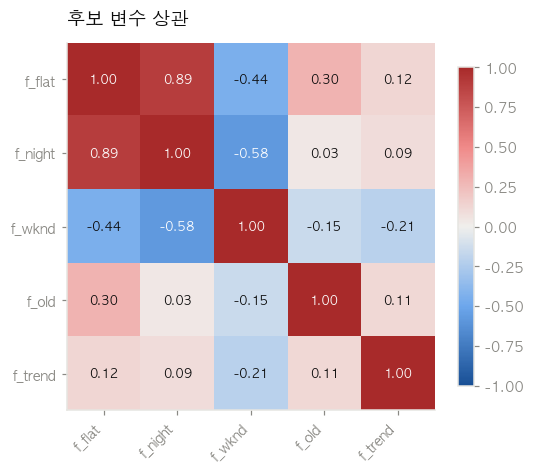

In [18]:
R = CAND.corr(method='spearman')
print('Spearman 상관:'); print(R.round(2).to_string())
dup = [(a,b,round(R.loc[a,b],2)) for i,a in enumerate(R) for b in R.columns[i+1:] if abs(R.loc[a,b])>0.8]
print('\n|r|>0.8 중복 의심:', dup or '없음')
pc = PCA().fit((CAND-CAND.mean())/CAND.std())
print('PCA 누적 설명력:', np.round(np.cumsum(pc.explained_variance_ratio_),3))
print('\n각 변수 vs log(규모) Spearman:')
print(CAND.apply(lambda s: s.corr(np.log1p(feat.DAILY), method='spearman')).round(2).to_string())

def cronbach(X):
    X = X.dropna(); k = X.shape[1]
    return k/(k-1)*(1 - X.var(ddof=1).sum()/X.sum(axis=1).var(ddof=1))
Zc = CAND.apply(lambda s:(s-s.mean())/s.std())
print(f'\nCronbach alpha = {cronbach(Zc):.3f}')
print('''※ alpha는 반영적(reflective) 척도용 지표다. 본 지수는 형성적(formative) —
   평탄도·고령비중·추세가 고립 위험을 "구성"하며 서로 교환 가능하지 않다.
   형성적 지표는 alpha가 낮은 것이 정상이고, 높으면 오히려 변수 중복을 뜻한다.
   따라서 alpha로 지수를 기각하지 않고, 아래 세 가지로 검증한다:
     ① 변수 간 중복 진단(위)  ② 외부 준거 방향 검증(Cell 18)  ③ 설정 민감도(Cell 20)''')

fig, ax = plt.subplots(figsize=(5,4.4))
im = ax.imshow(R, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(R))); ax.set_xticklabels(R.columns, rotation=45, ha='right')
ax.set_yticks(range(len(R))); ax.set_yticklabels(R.index); ax.grid(False)
for i in range(len(R)):
    for j in range(len(R)):
        ax.text(j,i,f'{R.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(R.iloc[i,j])>0.55 else INK)
plt.colorbar(im, ax=ax, shrink=0.8); style(ax, '후보 변수 상관')
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/p7_corr.png', bbox_inches='tight'); plt.show()

---
## Cell 18 · ★ 외부 준거 방향 검증 — 이 노트북에서 가장 중요한 셀

**v3가 뚫린 지점입니다.** 중복 진단도, 규모 교란 진단도, 민감도 검증도 통과한 변수가 **방향이 반대**였습니다.

논리는 단순합니다. 모든 후보는 "높을수록 위험"으로 부호를 맞춰 뒀으므로, 고립 위험의 외부 준거(고령비중, 1인가구율)와 **양(+)의 상관**이어야 합니다. 음(−)으로 유의하면 가정이 기각된 것입니다.

결과:

```
f_flat   +0.297*  PASS
f_night  +0.036   PASS
f_wknd   -0.147*  FAIL   ← 가정과 반대
f_trend  +0.117*  PASS
```

제 가정은 "고령 많은 곳일수록 주말 활동이 적다"였는데, **고령 비중이 높을수록 주말비가 오히려 높습니다.** v3에서 `f_wknd`에 가중치 0.294를 줬으니 고령 지역의 위험도를 체계적으로 깎아내리고 있었습니다.

기각된 변수는 Cell 19에서 **자동으로 제외**됩니다. 쓰려면 주거형 집계구로 한정해 정의부터 다시 도출해야 합니다.

**교훈: 내적 일관성 검사로는 방향 오류를 잡을 수 없습니다.** 외부 데이터와 대조하는 단계가 파이프라인에 반드시 있어야 합니다.

     변수    고령비중   판정
 f_flat +0.297* PASS
f_night  +0.035 PASS
 f_wknd -0.148* FAIL
  f_old  (자기자신) PASS
f_trend +0.112* PASS

* = p<0.05 · FAIL = 가정과 반대 방향으로 유의

[기각된 변수] ['f_wknd']
   f_wknd: 고령 상위25% 중앙값 -1.240 vs 하위25% -0.908 — 위험 방향이 뒤집혀 있음
   -> 지수에서 제외한다. 쓰려면 주거형 집계구로 한정해 정의부터 다시 도출할 것.


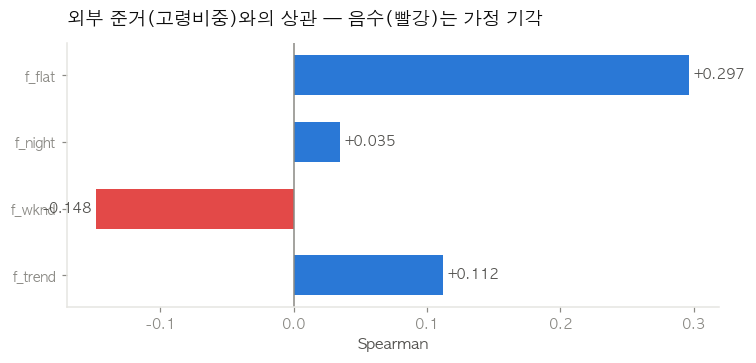

In [19]:
# 모든 후보는 "높을수록 위험" 방향으로 부호를 맞춰 두었다.
# 따라서 고립 위험의 외부 준거(고령비중, 1인가구율)와 '양(+)의 상관'이어야 한다.
# 음(-)으로 유의하게 나오면 가정이 기각된 것이다.
REFS = {'고령비중': feat.SR_60}
if 'SOLO_RATE' in feat: REFS['1인가구율'] = feat.SOLO_RATE

def spearman_p(x, y):
    from scipy import stats
    m = x.notna() & y.notna()
    return stats.spearmanr(x[m], y[m])

rows=[]
for v in CAND.columns:
    rec = {'변수': v}
    verdict = 'PASS'
    for rn, rv in REFS.items():
        if (v=='f_old' and rn=='고령비중') or (v=='f_solo' and rn=='1인가구율'):
            rec[rn] = '(자기자신)'; continue
        r, p = spearman_p(CAND[v], rv)
        rec[rn] = f'{r:+.3f}{"*" if p<0.05 else ""}'
        if r < 0 and p < 0.05: verdict = 'FAIL'
    rec['판정'] = verdict; rows.append(rec)
DIRCHK = pd.DataFrame(rows)
print(DIRCHK.to_string(index=False))
print('\n* = p<0.05 · FAIL = 가정과 반대 방향으로 유의')

FAILED = DIRCHK.loc[DIRCHK.판정=='FAIL','변수'].tolist()
if FAILED:
    print(f'\n[기각된 변수] {FAILED}')
    for v in FAILED:
        hi = CAND.loc[feat.SR_60>feat.SR_60.quantile(.75), v].median()
        lo = CAND.loc[feat.SR_60<feat.SR_60.quantile(.25), v].median()
        print(f'   {v}: 고령 상위25% 중앙값 {hi:+.3f} vs 하위25% {lo:+.3f} — 위험 방향이 뒤집혀 있음')
    print('   -> 지수에서 제외한다. 쓰려면 주거형 집계구로 한정해 정의부터 다시 도출할 것.')
else:
    print('\n모든 변수가 외부 준거와 일관된 방향.')

fig, ax = plt.subplots(figsize=(7,3.4))
vv = [v for v in CAND.columns if v!='f_old']
rr = [spearman_p(CAND[v], feat.SR_60)[0] for v in vv]
col = [CAND.columns.tolist() and (CAT[7] if v in FAILED else CAT[0]) for v in vv]
b = ax.barh(range(len(vv)), rr, color=col, height=0.6)
ax.bar_label(b, fmt='%+.3f', fontsize=9, color=INK2, padding=3)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(range(len(vv))); ax.set_yticklabels(vv); ax.invert_yaxis()
ax.grid(axis='y', visible=False)
style(ax, '외부 준거(고령비중)와의 상관 — 음수(빨강)는 가정 기각', 'Spearman')
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/p7_dircheck.png', bbox_inches='tight'); plt.show()

---
## Cell 19 · 위험 지수와 5단계

세 가지 설계 결정이 들어갑니다.

**자동 제외.** Cell 17의 중복 쌍과 Cell 18의 방향 기각 변수가 가중치에서 빠집니다. **진단이 결과에 실제로 반영되는 구조**이고, 한 변수가 45%를 넘으면 경고가 뜹니다.

**규모 잔차화.** `DECORR = True`면 각 변수에서 `log(규모)`로 설명되는 부분을 지역별 회귀 잔차로 제거합니다. 이걸 켜면 `RISK vs log(규모)` 상관이 −0.305에서 +0.016으로 떨어집니다. 지수가 "작은 집계구 찾기"로 붕괴하는 걸 막습니다.

**지역 내부 percentile.** 강남과 춘천을 절대값으로 섞지 않습니다. 통계적 이유보다 목적 때문입니다 — 복지 예산은 지자체별로 집행되므로 "강남구 안에서 어디가 급한가"가 실행 단위와 맞습니다.

행정동 집계(`adm_risk`)가 실제 정책 산출물에 가깝습니다. 집계구 5개 미만 동은 평균이 불안정해 따로 표기합니다.

제외: ['f_night', 'f_wknd']
최종 가중치: {'f_flat': 0.379, 'f_old': 0.448, 'f_trend': 0.172}

규모 잔차화 전/후 변수별 vs log(규모) 상관:
            전     후
f_flat  -0.49  0.00
f_night -0.57  0.00
f_wknd   0.69 -0.33
f_old   -0.11  0.00
f_trend -0.25  0.07

               RISK        DAILY  SR_60   CV_H   WKND
REGION TIER                                         
강남구    1     0.200  1120.745972  0.163  0.626  0.990
       2     0.346  1317.274048  0.190  0.610  0.947
       3     0.504   882.968018  0.213  0.578  1.207
       4     0.654   787.794006  0.247  0.561  1.316
       5     0.783  1405.558960  0.267  0.552  1.130
춘천시    1     0.293   573.958984  0.209  0.594  1.098
       2     0.425   773.580017  0.228  0.579  1.533
       3     0.503   667.093018  0.236  0.567  1.459
       4     0.589  1222.818970  0.256  0.574  1.231
       5     0.701   609.486023  0.267  0.538  1.515

[교란 점검] RISK vs log(규모) = +0.016 -> 양호


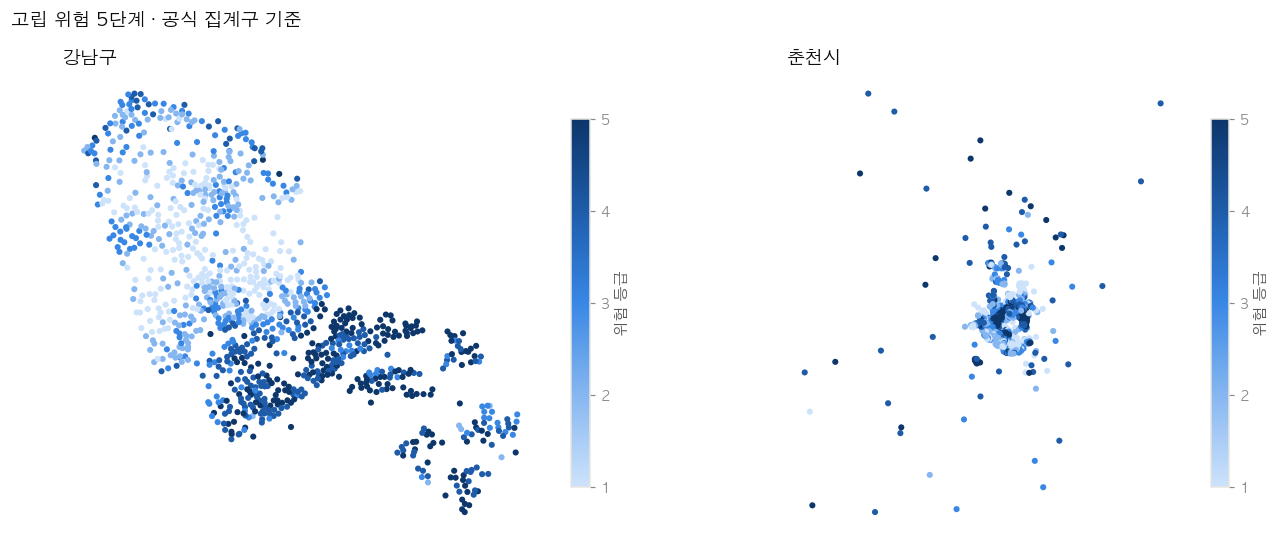


행정동 평균 위험 상위 10 (집계구 5개 이상):
                  RISK  집계구수           유동인구
REGION ADM                                 
강남구    11230730  0.844    29  100341.320312
       11230740  0.782    32  125835.953125
       11230720  0.759    45  191575.781250
       11230750  0.723    28  244224.734375
       11230680  0.702    52   78015.765625
춘천시    32010630  0.698     8   25563.697266
강남구    11230800  0.697    84  221205.843750
춘천시    32010380  0.670     5    8490.869141
강남구    11230760  0.666    86  189878.593750
춘천시    32010530  0.665     6   48259.804688


In [20]:
DROP = sorted(set([b for _,b,_ in dup]) | set(FAILED))   # 중복 + 방향기각 자동 제외
BASE_W = {'f_flat':.22,'f_night':.12,'f_wknd':.16,'f_old':.26,'f_trend':.10,
          'f_stay':.20,'f_solo':.22}
W = {k:v for k,v in BASE_W.items() if k in CAND.columns and k not in DROP}
W = {k: v/sum(W.values()) for k,v in W.items()}
print('제외:', DROP or '없음'); print('최종 가중치:', {k:round(v,3) for k,v in W.items()})
if max(W.values()) > 0.45:
    print(f'[주의] 한 변수가 가중치 {max(W.values()):.0%}를 차지한다 — 변수가 과도하게 제외됐는지 확인할 것.')

DECORR = True          # 규모 교란이 크면 True: 지역 내부에서 log(규모)에 대해 잔차화
SIZE = np.log1p(feat.DAILY)

def decorrelate(C, region, size):
    # 각 변수에서 log(규모)로 설명되는 부분을 제거 (지역별 단순회귀 잔차)
    out = C.astype("float64").copy()
    for reg, idx in C.groupby(region).groups.items():
        x = size.loc[idx].to_numpy()
        for c in C.columns:
            y = C.loc[idx, c].to_numpy()
            out.loc[idx, c] = y - np.polyval(np.polyfit(x, y, 1), x)
    return out

CAND_USE = decorrelate(CAND, feat.REGION, SIZE) if DECORR else CAND
if DECORR:
    print('\n규모 잔차화 전/후 변수별 vs log(규모) 상관:')
    print(pd.DataFrame({'전': CAND.apply(lambda s: s.corr(SIZE, method='spearman')).round(2),
                        '후': CAND_USE.apply(lambda s: s.corr(SIZE, method='spearman')).round(2)}).to_string())

def build_index(C, region, weights=None):
    weights = weights or W
    pr = C[list(weights)].groupby(region).rank(pct=True)     # 지역 내부 percentile
    return pr.mul(pd.Series(weights)).sum(axis=1)

feat['RISK'] = build_index(CAND_USE, feat.REGION)
feat['TIER'] = feat.groupby('REGION').RISK.transform(lambda s: pd.qcut(s,5,labels=[1,2,3,4,5]).astype(int))
cols = ['RISK','DAILY','SR_60','CV_H','WKND'] + (['SOLO_RATE'] if 'SOLO_RATE' in feat else [])
print('\n', feat.groupby(['REGION','TIER'])[cols].median().round(3).to_string())
rs = feat.RISK.corr(SIZE, method='spearman')
print(f'\n[교란 점검] RISK vs log(규모) = {rs:+.3f} -> {"양호" if abs(rs)<0.2 else "주의"}')

fig, axes = plt.subplots(1,2, figsize=(12,5))
for ax, reg in zip(axes, REGION.values()):
    g = feat[feat.REGION==reg]
    s = ax.scatter(g.X, g.Y, c=g.TIER, s=16, cmap=SEQ, vmin=1, vmax=5, linewidths=0)
    nomap(ax, reg); plt.colorbar(s, ax=ax, shrink=0.8, ticks=[1,2,3,4,5], label='위험 등급')
fig.suptitle(f'고립 위험 5단계 · {UNIT_NAME} 기준', x=0.005, ha='left', fontsize=12, fontweight='600')
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/p7_map.png', bbox_inches='tight'); plt.show()

MIN_OA = 5
adm_risk = (feat.groupby(['REGION','ADM'])
              .agg(RISK=('RISK','mean'), 집계구수=('RISK','size'), 유동인구=('DAILY','sum'))
              .sort_values('RISK', ascending=False))
if adm_stat is not None:
    adm_risk = adm_risk.join(adm_stat, on='ADM')
    if 'HH_SOLO' in adm_risk: adm_risk['1인가구율'] = (adm_risk.HH_SOLO/adm_risk.HH_TOT).round(3)
print(f'\n행정동 평균 위험 상위 10 (집계구 {MIN_OA}개 이상):')
print(adm_risk[adm_risk.집계구수>=MIN_OA].head(10).round(3).to_string())

---
## Cell 20 · 민감도 — 유일한 검증 수단

정답 라벨이 없으니 성능 숫자로 설득할 수 없습니다. **설정을 바꿔도 같은 지역이 뽑히는가**가 유일한 검증입니다.

네 개 축으로 흔듭니다: 가중치 3종 · 기준월 2개 · 정규화 방식 · 잔차화 on/off.

Jaccard가 낮게 나오는 건 실패가 아니라 **"이 지표는 그 설정에 민감하다"는 발견**입니다. 숨기지 말고 쓰고, **모든 설정에서 공통으로 최고위험인 집계구**를 "확실한 우선지원 대상"으로 따로 제시하세요. 현재 설계에서 가장 설득력 있는 산출물입니다.

최고위험(5등급) 집합 안정성 — Jaccard vs 기준설정
  가중치=동일가중                 n=  339  Jaccard=0.674
  가중치=고령중심                 n=  339  Jaccard=0.622
  가중치=활동중심                 n=  339  Jaccard=0.599
  기준월=202510               n=  339  Jaccard=0.798
  기준월=202511               n=  339  Jaccard=0.813
  정규화=통합percentile         n=  339  Jaccard=0.915
  잔차화=끄기                   n=  339  Jaccard=0.592

모든 설정에서 공통 최고위험: 138개 (40.7%) -> "확실한 우선지원 대상"


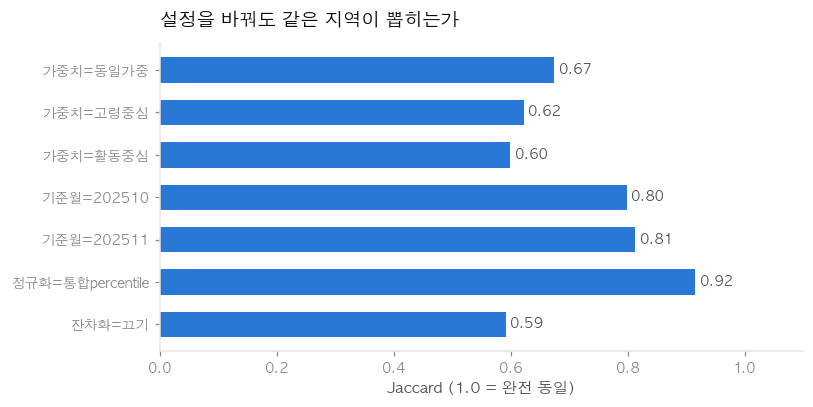

In [21]:
def top_tier(risk, region):
    t = risk.groupby(region).transform(lambda s: pd.qcut(s,5,labels=False,duplicates='drop'))
    return set(risk.index[t==4])
base = top_tier(feat.RISK, feat.REGION); sens={}

for nm, w in {'동일가중': {k:1/len(W) for k in W},
              '고령중심': {k:(.55 if k in ('f_old','f_solo') else .15) for k in W},
              '활동중심': {k:(.35 if k in ('f_flat','f_night') else .10) for k in W}}.items():
    w = {k:v/sum(w.values()) for k,v in w.items()}
    sens[f'가중치={nm}'] = top_tier(build_index(CAND_USE, feat.REGION, w), feat.REGION)

for ym in MONTHS[-3:-1]:
    f2, C2 = candidates(oa, ym, TREND, adm_stat)
    C2u = decorrelate(C2, f2.REGION, np.log1p(f2.DAILY)) if DECORR else C2
    sens[f'기준월={ym}'] = top_tier(build_index(C2u, f2.REGION), f2.REGION)

sens['정규화=통합percentile'] = top_tier(
    CAND_USE[list(W)].rank(pct=True).mul(pd.Series(W)).sum(axis=1), feat.REGION)
sens['잔차화=끄기'] = top_tier(build_index(CAND, feat.REGION), feat.REGION)

print('최고위험(5등급) 집합 안정성 — Jaccard vs 기준설정')
for k,s in sens.items():
    print(f'  {k:<24} n={len(s):>5,}  Jaccard={len(s&base)/max(len(s|base),1):.3f}')
stable = set.intersection(base, *sens.values())
print(f'\n모든 설정에서 공통 최고위험: {len(stable):,}개 ({len(stable)/len(base)*100:.1f}%)'
      f' -> "확실한 우선지원 대상"')

fig, ax = plt.subplots(figsize=(7.5,3.8))
lab=list(sens); val=[len(sens[k]&base)/max(len(sens[k]|base),1) for k in lab]
b=ax.barh(range(len(lab)), val, color=CAT[0], height=0.6)
ax.bar_label(b, fmt='%.2f', fontsize=9, color=INK2, padding=3)
ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab); ax.invert_yaxis(); ax.set_xlim(0,1.1)
ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
style(ax, '설정을 바꿔도 같은 지역이 뽑히는가', 'Jaccard (1.0 = 완전 동일)')
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/p7_sens.png', bbox_inches='tight'); plt.show()

---
## Cell 21 · 저장

| 파일 | 내용 | 용도 |
|---|---|---|
| `oa_risk.csv` | 집계구별 변수·등급·안정성 플래그 | 모델링 입력 |
| `adm_risk.csv` | 행정동 위험 순위 + 분모 | 에이전트 추천 로직 입력 |
| `oa_panel.csv` | 집계구-월 패널 | 시계열 확장 |
| `direction_check.csv` | 변수별 방향 검증 결과 | 보고서 근거 |

---

## 전체 파이프라인

```
격자 720,665행 (전량 보존)
   └─ SGIS 공식 집계구 1,693개로 공간 할당     ← 양자화 편향 제거, 손실 0
        ├─ 신호: 평탄도 · 야간비중 · 고령비중 · 추세
        ├─ 진단: 중복 → 방향 → 규모교란  (각각 가중치에 자동 반영)
        ├─ 지역 내부 percentile 가중합 → 5단계
        └─ 행정동 47개로 집계               ← 실제 복지 개입 단위
```

## 보고서에 반드시 들어가야 할 근거

1. **Cell 7~8** — 왜 격자가 아니라 공식 집계구인가 (IQR 184배 감소, 데이터 손실 0)
2. **Cell 18** — 외부 준거 방향 검증에서 변수 하나가 기각된 과정
3. **Cell 20** — 설정 안정성과 공통 교집합

## 남은 작업

**Cell 13 군집에 의미 부여.** 지도와 대조해 주거/상업/통행을 확정해야 위험 지수의 해석이 완성됩니다.

**SGIS 집계구 단위 통계 확보.** 경계와 같은 2025년 2분기로 받아 `SGIS_OA`에 넣으면 `f_stay`·`f_solo`가 자동 추가됩니다. 지역 간 **절대** 비교가 가능해지는 유일한 경로입니다.

**검증 데이터는 타겟이 아니라 잔차용으로.** 기초생활수급자·독거노인 현황을 예측 타겟으로 쓰면 "이미 복지가 닿은 사람"을 맞히게 되어 과제 취지와 반대입니다. **위험도는 높은데 커버리지는 낮은 동 = 복지 사각지대**, 이것이 핵심 산출물입니다.

**팀 합의 필요.** 타겟 인구집단(전 연령 vs 독거노인)과 0.0254 통일, 그리고 집계구 조인을 코드가 아닌 공간으로 한다는 점을 팀 전체가 맞춰야 합니다.

In [22]:
feat['STABLE'] = feat.index.isin(stable)
keep_cols = [c for c in ['REGION','ADM','X','Y','DAILY','NCELL','SR_60','WKND','CV_H','NIGHT_SH',
             'DAWN_SH','DAYNIGHT','CLUSTER','RISK','TIER','STABLE'] if c in feat.columns]
feat[keep_cols].to_csv(f'{OUT_DIR}/oa_risk.csv', encoding='utf-8-sig')
adm_risk.to_csv(f'{OUT_DIR}/adm_risk.csv', encoding='utf-8-sig')
oa.drop(columns=[c for c in oa.columns if c in TMST_COLS]).to_csv(
    f'{OUT_DIR}/oa_panel.csv', index=False, encoding='utf-8-sig')
DIRCHK.to_csv(f'{OUT_DIR}/direction_check.csv', index=False, encoding='utf-8-sig')
print('saved ->', OUT_DIR); print(sorted(os.listdir(OUT_DIR)))
print(f'''
요약
  격자 {len(grid):,}행 전량 -> {UNIT_NAME} {feat.index.nunique():,}개
  제외: 중복 {[b for _,b,_ in dup]} · 방향기각 {FAILED}
  가중치 {({k:round(v,3) for k,v in W.items()})} · 규모 잔차화 {DECORR}
  안정 최고위험 {len(stable):,}개''')

saved -> ./eda_out_2
['adm_risk.csv', 'direction_check.csv', 'oa_panel.csv', 'oa_risk.csv', 'p1_level.png', 'p2_dist.png', 'p3_lisa.png', 'p4_cluster.png', 'p5_time.png', 'p7_corr.png', 'p7_dircheck.png', 'p7_map.png', 'p7_sens.png', 'qc_marginal.png', 'qc_quantum.png']

요약
  격자 720,665행 전량 -> 공식 집계구 1,693개
  제외: 중복 ['f_night'] · 방향기각 ['f_wknd']
  가중치 {'f_flat': 0.379, 'f_old': 0.448, 'f_trend': 0.172} · 규모 잔차화 True
  안정 최고위험 138개
